# Problem 4.3

Consider the function from Ex. 4.1,

$$f(x_1, x_2) = x_1^3 + 2 x_1 x_2^2 - x_2^3 - 20 x_1.$$

Find the critical points of this function analytically and classify them. What is the global minimum of this function?

In [29]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Approach

In [30]:
def f(x):
    x1, x2 = x
    return x1 ** 3 + 2 * x1 * x2 ** 2 - x2 ** 3 - 20 * x1

def contour(f, xlim, ylim, n=200, levels=40, ax=None):
    """Contour plot of a 2D function f(x) with x = [x1, x2]; returns the axes."""
    x1, x2 = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    z = np.vectorize(lambda a, b: f(np.array([a, b])))(x1, x2)
    if ax is None:
        _, ax = plt.subplots()
    ax.contour(x1, x2, z, levels=levels)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    return ax

# contour(f, (-6, 6), (-6, 6)) once you have candidate points

In [31]:
# find critical points analytically

#define the gradient and Hessian of f
def grad(x):
    x1, x2 = x
    df_dx1 = 3 * x1 ** 2 + 2 * x2 ** 2 - 20
    df_dx2 = 4 * x1 * x2 - 3 * x2 ** 2
    return np.array([df_dx1, df_dx2])

def hessian(x):
    x1, x2 = x
    d2f_dx1dx1 = 6 * x1
    d2f_dx1dx2 = 4 * x2
    d2f_dx2dx1 = 4 * x2
    d2f_dx2dx2 = 4 * x1 - 6 * x2
    return np.array([[d2f_dx1dx1, d2f_dx1dx2],
                     [d2f_dx2dx1, d2f_dx2dx2]])

# find the critical points by solving grad(f) = 0

# example given in the book. there are four critical points
critical_points = [
    np.array([-2*np.sqrt(5/3), 0]),
    np.array([2*np.sqrt(5/3), 0]),
    np.array([6*np.sqrt(5/59), 8*np.sqrt(5/59)]),
    np.array([-6*np.sqrt(5/59), -8*np.sqrt(5/59)])
]

# see if the critical points are minima, maxima, or saddle points by checking the eigenvalues of the Hessian
for point in critical_points:
    hess = hessian(point)
    eigenvalues = np.linalg.eigvals(hess)
    if np.all(eigenvalues > 0):
        print(f"Point {np.round(point, 3)} is a local minimum.")
    elif np.all(eigenvalues < 0):
        print(f"Point {np.round(point, 3)} is a local maximum.")
    else:
        print(f"Point {np.round(point, 3)} is a saddle point.")

Point [-2.582  0.   ] is a local maximum.
Point [2.582 0.   ] is a local minimum.
Point [1.747 2.329] is a saddle point.
Point [-1.747 -2.329] is a saddle point.


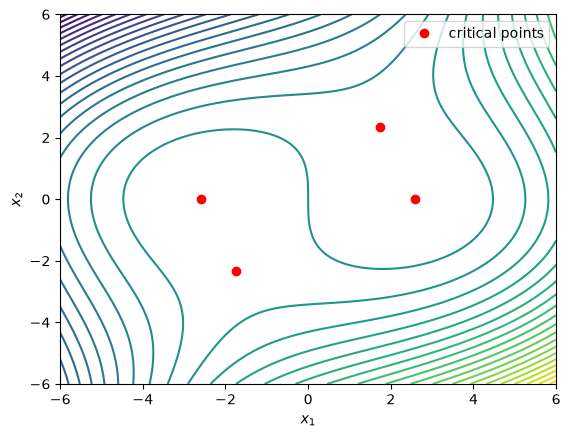

In [32]:
ax = contour(f, (-6, 6), (-6, 6))
pts = np.array(critical_points)                      # shape (n_points, 2)
ax.plot(pts[:, 0], pts[:, 1], "ro", label="critical points")
ax.legend()
plt.show()

## Results

see above. the four critical points have been identified and classified. we can also see that the only identified minimum is only a local minimum. so there is no global minimum.

## Interpretation

itentifying critical points by hand not efficient for large problems. a critical point is also not always a minimum. therefore we always need to check the hessian to ensure that we found a minimum and not a saddle point or a maximum. however, a minimum can be local and therefor not be the best solution to a problem.